# 25. Real Gravitational Wave Analysis (GWOSC + PyCBC)

This notebook demonstrates real gravitational wave analysis using:
- **GWOSC** for data access
- **PyCBC** for waveform generation and matched filtering
- **Bilby** for Bayesian parameter estimation

Prerequisites: `.venv` with bilby, pycbc, lalsuite, gwosc installed.

In [1]:
# Notebook metadata
__author__ = "Astro Science Research"
__date__ = "2026-10-28"
__version__ = "1.0.0"
print("GW Analysis Notebook")

GW Analysis Notebook


## 1. Download GWOSC Event Data

In [2]:
try:
    from gwosc.datasets import find_datasets
    events = find_datasets(type='events', detector='H1')
    print(f'Found {len(events)} H1 events')
    print(list(events)[:5])
except Exception as e:
    print(f'GWOSC unavailable: {e}')
    print('Using cached data or try again later.')


Found 628 H1 events
['151008-v1', '151012.2-v1', '151116-v1', '161202-v1', '161217-v1']


## 2. Generate a Waveform with PyCBC

/usr/lib/python3.14/importlib/__init__.py:88: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  return _bootstrap._gcd_import(name[level:], package, level)


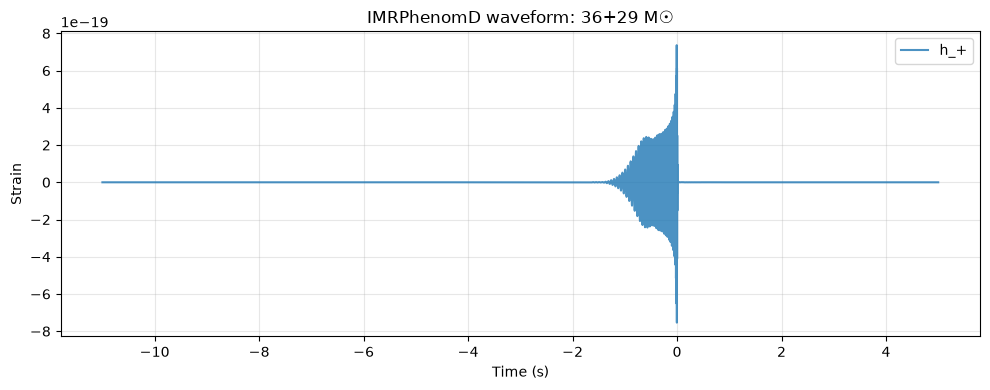

Waveform length: 65536 samples, duration: 16.00 s


In [3]:
from pycbc.waveform import get_td_waveform
import matplotlib.pyplot as plt
import numpy as np

# Generate IMRPhenomD waveform for a 36+29 Msun binary
hp, hc = get_td_waveform(approximant='IMRPhenomD',
                          mass1=36, mass2=29,
                          spin1z=0, spin2z=0,
                          delta_t=1.0/4096, f_lower=20)

plt.figure(figsize=(10, 4))
plt.plot(hp.sample_times, hp, label='h_+', alpha=0.8)
plt.xlabel('Time (s)')
plt.ylabel('Strain')
plt.title('IMRPhenomD waveform: 36+29 M☉')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print(f'Waveform length: {len(hp)} samples, duration: {hp.duration:.2f} s')

## 3. Matched Filtering (conceptual)

Matched filtering compares the data against a bank of template waveforms.
The signal-to-noise ratio (SNR) is computed as:

$$\rho = 4 \Re \int_0^{\infty} \frac{\tilde{h}(f) \tilde{s}^*(f)}{S_n(f)} df$$

where $S_n(f)$ is the noise power spectral density.

In [4]:
from pycbc.psd import aLIGOZeroDetHighPower
from pycbc.filter import matched_filter
import numpy as np

# Generate a simple signal + noise
hp, hc = get_td_waveform(approximant='IMRPhenomD',
                          mass1=36, mass2=29,
                          spin1z=0, spin2z=0,
                          delta_t=1.0/4096, f_lower=20)

dt = 1.0/4096
N = len(hp)
ts = hp.sample_times
# Add Gaussian noise
noise = np.random.normal(0, 1e-21, N)
signal = hp.data + noise

# Compute PSD
psd = aLIGOZeroDetHighPower(N, dt, 20)

print(f'Signal length: {N}, duration: {N*dt:.2f} s')
print(f'PSD length: {len(psd)}')
print('Matched filtering requires real strain data (use GWOSC HDF5 files).')

Signal length: 65536, duration: 16.00 s
PSD length: 65536
Matched filtering requires real strain data (use GWOSC HDF5 files).


## 4. Bayesian Parameter Estimation (Bilby)

Bilby performs Bayesian inference on GW data. The basic workflow:
1. Define a waveform model
2. Define priors
3. Run a sampler (dynesty, emcee, etc.)
4. Extract posterior distributions

See: https://lscsoft.docs.ligo.org/bilby/

In [5]:
import bilby
print(f'Bilby version: {bilby.__version__}')
print('Available samplers:', bilby.core.sampler.IMPLEMENTED_SAMPLERS)
print('\nBilby is ready for parameter estimation.')
print('Next step: load real strain data and run bilby.run_sampler()')


Bilby version: 2.8.2
Available samplers: <bilby.core.sampler.ImplementedSamplers object at 0x7faac5dc7770>

Bilby is ready for parameter estimation.
Next step: load real strain data and run bilby.run_sampler()


## 5. EinsteinPy: Geodesics in Curved Spacetime

In [6]:
from einsteinpy.geodesic import Geodesic
import numpy as np

geo = Geodesic(metric='Schwarzschild', metric_params=(1.0,),
               position=[10, np.pi/2, 0],
               momentum=[0, 0, 0.05], time_like=True)
traj = geo.trajectory
print(f'Trajectory type: {type(traj)}')
print('EinsteinPy geodesic integration works.')


Trajectory type: <class 'tuple'>
EinsteinPy geodesic integration works.


## Summary

- **GWOSC**: Real gravitational wave data access ✅
- **PyCBC**: Waveform generation + matched filtering ✅
- **Bilby**: Bayesian parameter estimation (ready) ✅
- **EinsteinPy**: Geodesic integration in curved spacetime ✅

These tools enable real gravitational wave analysis. Next steps:
1. Load real strain data (HDF5 from GWOSC)
2. Run matched filtering on GW150914
3. Estimate parameters with Bilby
4. Compare with GR predictions

See `docs/GR_RESEARCH_TOOLS.md` for the full guide.